# Лабораторная работа № 01 — прикладная статистика
## Sprint 2. Генератор количества строк

**Цель:** получить случайные значения с таким же распределением, как у числа строк в первом спринте.

<a id="description"></a>
## 1. Random Variable 01 — количество строк

### Description

В первом спринте я измеряла, сколько строк занимает один из 54 текстовых фрагментов в **DejaVu Serif**.

Здесь $Y$ — число строк у случайно выбранного фрагмента. Каждый фрагмент выбирается с вероятностью $1/54$. Генератор будет воспроизводить распределение $Y$, а не создавать новый текст.

Для дискретной величины вероятность оцениваю по частотам:

$$\hat p_k=P(Y=k)\approx\frac{n_k}{54},\qquad \sum_k\hat p_k=1.$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from src.sprint2_generators import inverse_cdf, alias_sample

plt.rcParams.update({
    "figure.figsize": (9, 4), "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.18,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 115
})

layout = pd.read_csv("data/layout.csv")
real = layout.loc[layout["font"] == "DejaVu Serif", "lines"].to_numpy()
counts = pd.Series(real).value_counts().sort_index()
values = counts.index.to_numpy()
p = counts.to_numpy() / counts.sum()
cdf = np.cumsum(p)

table = pd.DataFrame({
    "Число строк": values, "Частота": counts.to_numpy(),
    "Вероятность": p, "F(k)": cdf
})
display(table.round(4))
print("Число фрагментов:", len(real), "| Сумма вероятностей:", round(sum(p), 6))

,Число строк,Частота,Вероятность,F(k)
0,2,8,0.1481,0.1481
1,3,20,0.3704,0.5185
2,4,12,0.2222,0.7407
3,5,9,0.1667,0.9074
4,6,2,0.0370,0.9444
5,7,1,0.0185,0.9630
6,10,2,0.0370,1.0000


Число фрагментов: 54 | Сумма вероятностей: 1.0


<a id="math"></a>
## 2. Метод обратной функции

### Math desc

Сначала считаю накопленные вероятности:

$$F(k)=P(Y\leq k)=\sum_{y_i\leq k}p_i.$$

Генерирую $U\sim U[0,1)$ и беру первое значение $k$, для которого $F(k)>U$.

$$Y=F^{-1}(U)=\min\{k:F(k)>U\}.$$

**Почему это работает:** для значения $k$ отведён отрезок длины $p_k$ на интервале от 0 до 1. Равномерное число попадает туда с вероятностью $p_k$.

### Code

Функция `inverse_cdf` находится в `src/sprint2_generators.py`. Она строит границы интервалов и находит, куда попало случайное число.

In [2]:
u = np.random.default_rng(13).random(8)
example = inverse_cdf(values, p, 8, seed=13)
display(pd.DataFrame({"U": u, "Строки": example}).round(4))

generated = inverse_cdf(values, p, 15000, seed=42)
print("Сгенерировано значений:", len(generated))

,U,Строки
0,0.8648,5
1,0.8553,5
2,0.8110,5
3,0.2614,3
4,0.0772,2
5,0.9465,7
6,0.6138,4
7,0.0026,2


Сгенерировано значений: 15000


<a id="tests"></a>
## 3. Tests — сравнение с данными

Генератор должен выдавать допустимые значения, а их доли, среднее и разброс должны быть близки к исходным.

Для проверки частот использую критерий $\chi^2$:

$$\chi^2=\sum_k\frac{(O_k-E_k)^2}{E_k},\qquad E_k=n\hat p_k.$$

Здесь проверяется **соответствие генератора частотам исходной таблицы**, а не то, подходит ли модель для всех возможных книг.

In [3]:
def metrics(data):
    return {
        "Среднее, строк": np.mean(data),
        "Ст. отклонение": np.std(data, ddof=0),
        "Медиана": np.median(data),
        "Доля с 5+ строками": np.mean(data >= 5)
    }

alias_generated = alias_sample(values, p, 15000, seed=42)

summary = pd.DataFrame({
    "Исходные данные": metrics(real),
    "Обратная функция": metrics(generated),
    "Псевдонимы": metrics(alias_generated)
}).T
display(summary.round(4))

test_results = []
for label, sample in [("Обратная функция", generated), ("Псевдонимы", alias_generated)]:
    observed = np.array([(sample == k).sum() for k in values])
    chi, pv = stats.chisquare(observed, f_exp=len(sample) * p)
    tv = 0.5 * np.abs(observed / len(sample) - p).sum()
    test_results.append([label, chi, pv, tv])
display(pd.DataFrame(test_results,
    columns=["Метод", "chi2", "p-value", "Расстояние TV"]).round(5))

,"Среднее, строк",Ст. отклонение,Медиана,Доля с 5+ строками
Исходные данные,3.8519,1.6601,3.0,0.2593
Обратная функция,3.8443,1.6469,3.0,0.2555
Псевдонимы,3.8239,1.6189,3.0,0.2537


,Метод,chi2,p-value,Расстояние TV
0,Обратная функция,2.23788,0.89657,0.00576
1,Псевдонимы,7.90987,0.24478,0.00553


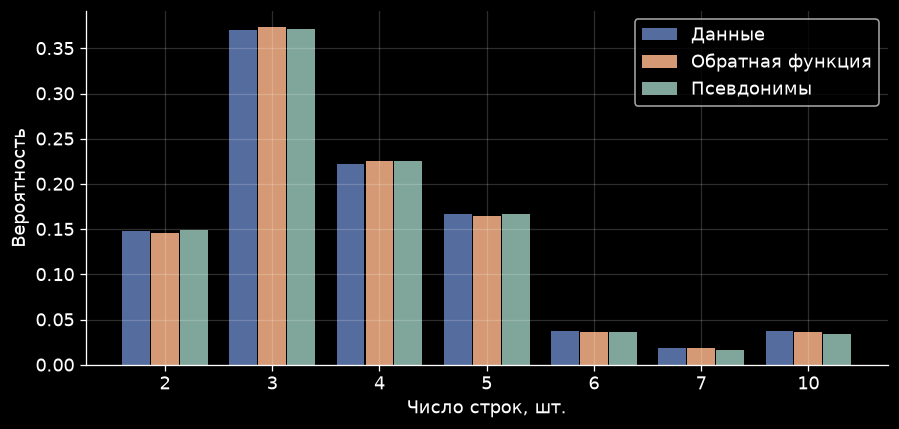

In [4]:
x = np.arange(len(values))
fig, ax = plt.subplots()
ax.bar(x - 0.27, p, 0.26, label="Данные", color="#546C9E")
ax.bar(x, [(generated == k).mean() for k in values], 0.26,
       label="Обратная функция", color="#D59A75")
ax.bar(x + 0.27, [(alias_generated == k).mean() for k in values], 0.26,
       label="Псевдонимы", color="#80A59A")
ax.set_xticks(x, values)
ax.set(xlabel="Число строк, шт.", ylabel="Вероятность")
ax.legend()
plt.show()

**Вывод.** Среднее, разброс и частоты получаются близкими к исходным. Небольшая разница возникает из-за случайной генерации. Если $p$-value больше 0,05, критерий не обнаружил значимых расхождений с заданным распределением.

<a id="alias"></a>
## 4. Дополнительный метод — псевдонимы

### Math desc

Метод псевдонимов сначала строит таблицу из $m$ одинаковых по вероятности столбцов. В каждом столбце хранятся порог $q_i$ и второй вариант — `alias`.

Случайно выбираем столбец $i$, затем число $V\sim U[0,1)$:
- если $V<q_i$, берём $i$;
- иначе берём `alias[i]`.

Вероятность получить значение $j$:

$$P(Y=y_j)=\frac1m\left(q_j+\sum_{i:\,\operatorname{alias}(i)=j}(1-q_i)\right)=p_j.$$

Подготовка таблицы занимает $O(m)$, а одно значение генерируется за $O(1)$. Для обратной функции поиск по накопленным вероятностям занимает $O(\log m)$ на одно значение.

### Code

Реализация — `make_alias_table` и `alias_sample` в `src/sprint2_generators.py`.

In [5]:
from src.sprint2_generators import make_alias_table

cut, aliases = make_alias_table(p)
display(pd.DataFrame({
    "Значение": values, "Порог": cut,
    "Псевдоним": values[aliases]
}).round(4))
print("Первые 12 значений:", alias_generated[:12])

,Значение,Порог,Псевдоним
0,2,1.0000,2
1,3,0.9630,2
2,4,0.9815,3
3,5,0.4259,4
4,6,0.2593,3
5,7,0.1296,3
6,10,0.2593,5


Первые 12 значений: [2 3 6 4 4 5 2 3 3 2 4 5]


<a id="autotests"></a>
## 5. Автотесты

Проверяю допустимые значения, повторяемость по `seed`, частоты, некорректные вероятности и случай с одним возможным исходом.

In [6]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_sprint2_generators.py"],
    capture_output=True, text=True
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
assert result.returncode == 0

...........                                                              [100%]
11 passed in 0.06s



<a id="resume"></a>
## 6. Lab resume

1. Генератор воспроизводит распределение числа строк для 54 выбранных фрагментов.
2. Сгенерированные средние и частоты близки к исходным; автотесты проверяют реализацию.
3. Метод обратной функции проще, метод псевдонимов удобнее при большом числе генераций.

Результаты относятся к изученным фрагментам и DejaVu Serif. Генератор не создаёт текст и не рассчитывает его реальную вёрстку заново.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| 1 — описание величины | [§1](#description) | — | число строк, частоты |
| 2 — математика и метод | [§2](#math) | — | обратная функция |
| 3 — проверка генератора | [§3](#tests) | — | метрики, график, $\chi^2$ |
| 4 — дополнительный метод | [§4](#alias) | — | псевдонимы |
| 5 — автотесты | [§5](#autotests) | — | pytest |


### Источники

1. L. Devroye, *Non-Uniform Random Variate Generation* (1986), раздел об обратной функции — [книга](https://luc.devroye.org/books-luc.html).
2. A. J. Walker, *An Efficient Method for Generating Discrete Random Variables with General Distributions* (1977) — [ACM](https://doi.org/10.1145/355744.355749).
3. M. D. Vose, *A Linear Algorithm for Generating Random Numbers with a Given Distribution* (1991) — [IEEE](https://doi.org/10.1109/32.92917).
4. [NumPy Generator API](https://numpy.org/doc/stable/reference/random/generator.html).